In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

# Ekran görüntüsündeki klasör yoluna göre ayarlandı:
data_dir = '/content/drive/MyDrive/dermAI/dataset/dermAi dataset'

# Klasörlerin doğru okunduğunu kontrol edelim
print("Sınıflar:", os.listdir(data_dir))
for folder in os.listdir(data_dir):
    folder_path = os.path.join(data_dir, folder)
    if os.path.isdir(folder_path):
        print(f"{folder}: {len(os.listdir(folder_path))} görsel")

Mounted at /content/drive
Sınıflar: ['PSORIASIS', 'Eczema', 'Normal']
PSORIASIS: 1586 görsel
Eczema: 1544 görsel
Normal: 2983 görsel


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

data_dir = '/content/drive/MyDrive/dermAI/dataset/dermAi dataset'
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
print("Sınıf İndeksleri:", list(enumerate(class_names)))

counts = {
    'Eczema': 1544,
    'Normal': 2983,
    'PSORIASIS': 1586
}
total = sum(counts.values())
class_weights = {
    i: total / (3.0 * counts[name]) for i, name in enumerate(class_names)
}
print("Hesaplanan Sınıf Ağırlıkları:", class_weights)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 6113 files belonging to 3 classes.
Using 4891 files for training.
Found 6113 files belonging to 3 classes.
Using 1222 files for validation.
Sınıf İndeksleri: [(0, 'Eczema'), (1, 'Normal'), (2, 'PSORIASIS')]
Hesaplanan Sınıf Ağırlıkları: {0: 1.3197322970639034, 1: 0.6830930830260364, 2: 1.2847835224884405}


In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.1),
])

base_model = tf.keras.applications.EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation='softmax')(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

checkpoint_cb = keras.callbacks.ModelCheckpoint(
    '/content/drive/MyDrive/dermAI_model_v1.keras',
    save_best_only=True,
    monitor='val_accuracy'
)

early_stopping_cb = keras.callbacks.EarlyStopping(
    patience=4,
    restore_best_weights=True,
    monitor='val_loss'
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=[checkpoint_cb, early_stopping_cb]
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 1028s 1s/step - accuracy: 0.8027 - loss: 0.5244 - val_accuracy: 0.8535 - val_loss: 0.3728
Epoch 2/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 16s 106ms/step - accuracy: 0.9139 - loss: 0.2796 - val_accuracy: 0.8797 - val_loss: 0.2924
Epoch 3/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 16s 104ms/step - accuracy: 0.9313 - loss: 0.2221 - val_accuracy: 0.9173 - val_loss: 0.2219
Epoch 4/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 15s 96ms/step - accuracy: 0.9378 - loss: 0.1993 - val_accuracy: 0.9059 - val_loss: 0.2204
Epoch 5/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 15s 96ms/step - accuracy: 0.9464 - loss: 0.1773 - val_accuracy: 0.9165 - val_loss: 0.2038
Epoch 6/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 15s 101ms/step - accuracy: 0.9538 - loss: 0.1649 - val_accuracy: 0.9198 - val_loss: 0.2071
Epoch 7/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 15s 97ms/step - accuracy: 0.9530 - loss: 0.1520 - val_accuracy: 0.9182 - val_loss: 0.1951
Epoch 8/15
153/153 ━━━━━━━━━━━━━━━━━

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Veri setini yeniden tanımla ve önbellekle
data_dir = '/content/drive/MyDrive/dermAI/dataset/dermAi dataset'
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
counts = {'Eczema': 1544, 'Normal': 2983, 'PSORIASIS': 1586}
total = sum(counts.values())
class_weights = {i: total / (3.0 * counts[name]) for i, name in enumerate(class_names)}

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

# Kaydedilmiş en iyi v1 modelini yükle
model = keras.models.load_model('/content/drive/MyDrive/dermAI_model_v1.keras')

# EfficientNetB0 temel katmanına eriş ve son 30 katmanın kilidini aç
base_model = model.layers[2]
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers[-30:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Çok düşük öğrenme oranı ile yeniden derle
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

checkpoint_ft = keras.callbacks.ModelCheckpoint(
    '/content/drive/MyDrive/dermAI_model_final.keras',
    save_best_only=True,
    monitor='val_accuracy'
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    patience=3,
    restore_best_weights=True,
    monitor='val_loss'
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=[checkpoint_ft, early_stopping_ft]
)

Found 6113 files belonging to 3 classes.
Using 4891 files for training.
Found 6113 files belonging to 3 classes.
Using 1222 files for validation.
Epoch 1/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 1171s 2s/step - accuracy: 0.9585 - loss: 0.1192 - val_accuracy: 0.9304 - val_loss: 0.1643
Epoch 2/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 15s 99ms/step - accuracy: 0.9669 - loss: 0.1048 - val_accuracy: 0.9304 - val_loss: 0.1641
Epoch 3/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - accuracy: 0.9701 - loss: 0.0955 - val_accuracy: 0.9329 - val_loss: 0.1595
Epoch 4/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 17s 111ms/step - accuracy: 0.9726 - loss: 0.0868 - val_accuracy: 0.9386 - val_loss: 0.1447
Epoch 5/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 19s 100ms/step - accuracy: 0.9755 - loss: 0.0763 - val_accuracy: 0.9378 - val_loss: 0.1448
Epoch 6/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 16s 105ms/step - accuracy: 0.9771 - loss: 0.0727 - val_accuracy: 0.9534 - val_loss: 0.1173
Epoch 7/10
153/153 ━━━━━━━━━━━━━━━━━━━━ 20s 101ms/step - accuracy: 0.9

Sınıflandırma Raporu:

              precision    recall  f1-score   support

      Eczema       0.85      0.99      0.92       275
      Normal       1.00      0.96      0.98       612
   PSORIASIS       0.98      0.91      0.95       335

    accuracy                           0.95      1222
   macro avg       0.94      0.96      0.95      1222
weighted avg       0.96      0.95      0.96      1222



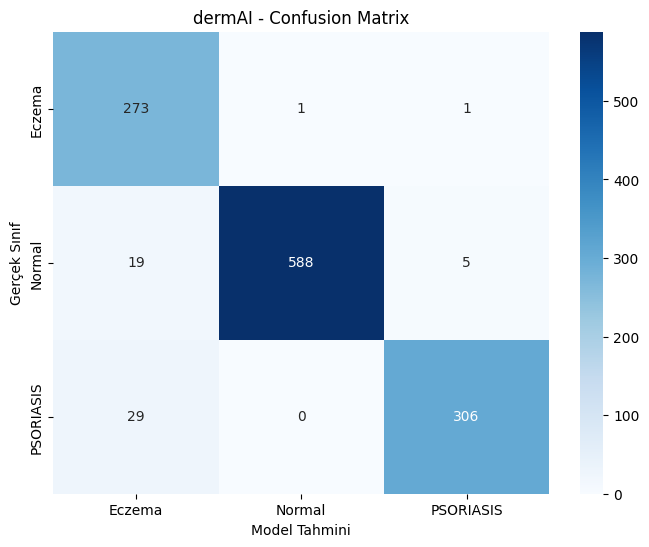

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# En iyi final modelini yükle
best_model = keras.models.load_model('/content/drive/MyDrive/dermAI_model_final.keras')

# Doğrulama seti üzerindeki gerçek etiketleri ve model tahminlerini topla
y_true = []
y_pred = []

for images, labels in val_ds:
    preds = best_model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

# Detaylı Precision, Recall, F1-Score tablosu
print("Sınıflandırma Raporu:\n")
print(classification_report(y_true, y_pred, target_names=class_names))

# Karmaşıklık Matrisi (Confusion Matrix) çizimi
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Model Tahmini')
plt.ylabel('Gerçek Sınıf')
plt.title('dermAI - Confusion Matrix')
plt.show()

In [ ]:
from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

# Bilgisayarından görsel yükle
uploaded = files.upload()

for filename in uploaded.keys():
    # Görseli modelin beklediği 224x224 boyutuna getir
    img = load_img(filename, target_size=(224, 224))
    img_array = img_to_array(img)
    img_batch = np.expand_dims(img_array, axis=0)  # (1, 224, 224, 3)

    # Tahmin yap
    predictions = best_model.predict(img_batch, verbose=0)[0]
    predicted_class = class_names[np.argmax(predictions)]
    confidence = 100 * np.max(predictions)

    # Görseli ve sonuçları ekrana bas
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Tahmin: {predicted_class} (%{confidence:.2f})")
    plt.show()

    print(f"\n--- {filename} İçin Olasılık Dağılımı ---")
    for name, prob in zip(class_names, predictions):
        print(f"{name}: %{prob*100:.2f}")